# 04. 수요·경쟁 가설 검증 (H1~H4)

2026년 2분기 한 시점의 상권들을 비교해서 수요(H1~H3)와 경쟁(H4) 가설을 검증합니다.
판정 기준은 2단계에서 데이터를 보기 전에 정한 그대로입니다.

| 가설 | 내용 | 판정 기준 |
|---|---|---|
| H1 | 직장인구가 많은 상권일수록 점포당 매출이 높다 | r ≥ 0.3, p < 0.05 |
| H2 | 06~14시 유동인구가 전체 유동인구보다 점포당 매출을 더 잘 설명한다 | 06~14시 유동인구의 r이 더 큼 |
| H3 | 지하철역·관공서가 있는 상권은 점포당 매출이 높다 | p < 0.05 (둘 다면 지지, 하나면 부분 지지) |
| H4 | 커피 점포가 많을수록 점포당 매출은 낮아진다 | 회귀에서 점포 수 계수 < 0, p < 0.05 |

모든 검증은 세 가지 버전으로 돌립니다. 판정은 "기본"으로 하고 나머지 둘은 결과가 처리 방법에 따라 바뀌는지 보는 용도입니다.
- 기본: 결제가 거의 안 잡힌 줄(점포당 분기 결제 90건 미만)을 뺀 것
- 결제부족 포함: 그 줄까지 다 넣은 것
- 시청역_8번 제외: 기본에서 시청역_8번만 뺀 것

점포당 매출과 인구, 점포 수는 모두 자연로그(ln)로 바꾼 값을 씁니다.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

load_dotenv('../.env')
url = URL.create(
    drivername='postgresql+psycopg2',
    username=os.environ['PGUSER'],
    password=os.environ['PGPASSWORD'],
    host=os.environ['PGHOST'],
    port=int(os.environ['PGPORT']),
    database=os.environ['PGDATABASE'],
)
engine = create_engine(url)

#### 코드 읽기
- `from scipy import stats`: 상관계수, t-test 같은 통계 검정 함수가 들어 있는 모듈입니다. `stats.pearsonr`, `stats.ttest_ind`처럼 씁니다.
- `import statsmodels.formula.api as smf`: 회귀분석 라이브러리입니다. `formula`가 붙은 쪽을 쓰면 `'y ~ x1 + x2'`처럼 식을 글자로 적어서 회귀를 돌릴 수 있습니다.
- 나머지는 03 노트북과 같습니다. 그래프 한글 폰트를 정하고 `.env`의 접속 정보로 DB 연결을 준비합니다.

## 0. 분석 대상 뷰 만들고 불러오기

In [2]:
with open('../sql/02_분석_대상.sql', encoding='utf-8') as f:
    sql = f.read()

with engine.begin() as conn:
    for statement in sql.split(';'):
        if statement.strip():
            conn.execute(text(statement))

all_rows = pd.read_sql('SELECT * FROM 분석_대상 WHERE 기준_년분기_코드 = 20262', engine)
print('2026Q2 매출 있는 상권:', len(all_rows))
print('그중 결제부족:', all_rows['결제부족'].sum())

2026Q2 매출 있는 상권: 1058
그중 결제부족: 50


#### 코드 읽기
- `open(...)`부터 `conn.execute(...)`까지: 02 노트북과 같은 방식입니다. SQL 파일을 읽고 세미콜론으로 잘라서 한 문장씩 실행합니다. 여기서는 `분석_대상` 뷰가 만들어집니다.
- `with engine.begin() as conn:`: `begin()`은 블록이 끝날 때 실행한 내용을 확정(commit)합니다. 중간에 에러가 나면 전부 취소됩니다.
- `if statement.strip():`: 파일 끝 세미콜론 뒤에 남는 빈 문자열은 실행하지 않고 넘어갑니다.
- `pd.read_sql(...)`: 뷰에서 2026년 2분기만 가져옵니다. 뷰도 테이블처럼 `SELECT`할 수 있습니다.
- `all_rows['결제부족'].sum()`: 결제부족은 0/1 컬럼이라 더하면 1인 줄의 개수가 됩니다.

In [3]:
# 세 가지 버전
base = all_rows[all_rows['결제부족'] == 0]
with_low = all_rows
no_city = base[base['상권_코드_명'] != '시청역_8번']

versions = {
    '기본': base,
    '결제부족 포함': with_low,
    '시청역_8번 제외': no_city,
}

for name, data in versions.items():
    print(name, len(data))

기본 1008
결제부족 포함 1058
시청역_8번 제외 1007


#### 코드 읽기
- `base = ...`: 결제부족이 0인 줄만 남긴 기본 데이터입니다.
- `with_low = all_rows`: 아무것도 안 뺀 데이터입니다.
- `no_city = base[base['상권_코드_명'] != '시청역_8번']`: `!=`는 "같지 않다"입니다. 기본 데이터에서 시청역_8번만 뺍니다.
- `versions = {...}`: 이름과 데이터를 딕셔너리로 묶어 둡니다. 아래에서 for문 하나로 세 버전을 차례로 돌리기 위해서입니다.
- `for name, data in versions.items():`: `.items()`는 (이름, 데이터) 쌍을 하나씩 꺼내 줍니다.

## 1. 설명 변수끼리의 관계

회귀분석에 넣을 변수끼리 상관이 너무 높으면 계수가 불안정해집니다(다중공선성).
매출을 보기 전에 설명 변수끼리만 먼저 봅니다.

In [4]:
x_cols = ['ln_직장인구', 'ln_오전점심_유동인구', 'ln_유동인구', 'ln_상주인구',
          'ln_점포_수', '지하철역_수', '관공서_수']
base[x_cols].corr().round(2)

,ln_직장인구,ln_오전점심_유동인구,ln_유동인구,ln_상주인구,ln_점포_수,지하철역_수,관공서_수
ln_직장인구,1.00,0.32,0.27,0.07,0.68,0.38,0.41
ln_오전점심_유동인구,0.32,1.00,0.99,0.63,0.52,0.23,0.29
ln_유동인구,0.27,0.99,1.00,0.67,0.49,0.20,0.27
ln_상주인구,0.07,0.63,0.67,1.00,0.23,0.02,0.16
ln_점포_수,0.68,0.52,0.49,0.23,1.00,0.44,0.46
지하철역_수,0.38,0.23,0.20,0.02,0.44,1.00,0.32
관공서_수,0.41,0.29,0.27,0.16,0.46,0.32,1.00


#### 코드 읽기
- `x_cols = [...]`: 설명 변수 이름 목록입니다. H2 비교용으로 전체 유동인구도 같이 넣었습니다.
- `base[x_cols].corr()`: 고른 컬럼끼리 모든 쌍의 피어슨 상관계수를 표로 만듭니다. 대각선은 자기 자신이라 항상 1입니다.

ln 직장인구와 ln 점포 수의 상관이 0.68로 가장 높습니다. 직장인이 많은 곳에 카페도 많다는 뜻입니다. 둘을 같은 회귀에 넣으면 효과를 서로 나눠 가져서 하나만 넣었을 때보다 계수가 작게 나올 수 있습니다.

전체 유동인구와 오전·점심 유동인구는 0.99로 사실상 같은 변수라서 회귀에는 오전·점심 유동인구 하나만 넣습니다. 나머지 쌍은 0.7 미만이라 같이 넣어도 괜찮다고 봤습니다.

## 2. H1. 직장인구와 점포당 매출

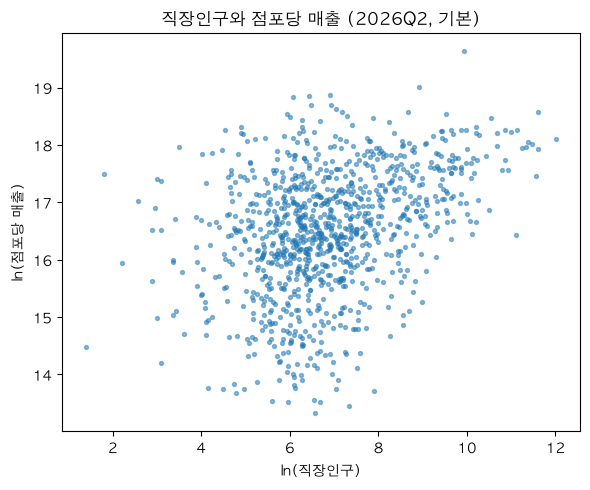

In [5]:
plt.figure(figsize=(6, 5))
plt.scatter(base['ln_직장인구'], base['ln_점포당_매출'], s=8, alpha=0.5)
plt.xlabel('ln(직장인구)')
plt.ylabel('ln(점포당 매출)')
plt.title('직장인구와 점포당 매출 (2026Q2, 기본)')
plt.tight_layout()
plt.show()

#### 코드 읽기
- `plt.scatter(x, y, s=8, alpha=0.5)`: 산점도를 그립니다. `s`는 점 크기, `alpha`는 투명도(0~1)입니다. 점이 1,000개 넘게 겹쳐서 반투명하게 했습니다.
- 축이 로그 값이라 x가 1 늘면 직장인구가 약 2.7배(e배) 많다는 뜻입니다.

In [6]:
def corr_by_version(x_col, y_col='ln_점포당_매출'):
    rows = []
    for name, data in versions.items():
        d = data.dropna(subset=[x_col, y_col])
        r, p = stats.pearsonr(d[x_col], d[y_col])
        rows.append({'버전': name, '상권_수': len(d), 'r': round(r, 3), 'p값': p})
    return pd.DataFrame(rows)

corr_by_version('ln_직장인구')

,버전,상권_수,r,p값
0,기본,1006,0.368,1.539673e-33
1,결제부족 포함,1056,0.365,1.538109e-34
2,시청역_8번 제외,1005,0.364,7.198942e-33


#### 코드 읽기
- `def corr_by_version(x_col, y_col='ln_점포당_매출'):`: 변수 이름을 받아서 세 버전의 상관계수를 표로 돌려주는 함수입니다. H2에서도 다시 쓰려고 함수로 만들었습니다. `y_col=...`처럼 기본값을 주면 안 넘겼을 때 그 값을 씁니다.
- `rows = []`: 결과를 한 줄씩 담을 빈 리스트입니다.
- `data.dropna(subset=[x_col, y_col])`: 두 컬럼 중 하나라도 비어 있는 줄은 뺍니다. `pearsonr`은 빈 값이 있으면 결과가 nan이 됩니다.
- `r, p = stats.pearsonr(...)`: 상관계수와 p값 두 개를 돌려줍니다. p값은 "실제로는 상관이 0인데 우연히 이만큼 나올 확률"입니다.
- `rows.append({...})`: 결과를 딕셔너리 하나로 만들어 리스트에 추가합니다.
- `pd.DataFrame(rows)`: 딕셔너리 리스트를 표로 바꿉니다. 딕셔너리 키가 컬럼 이름이 됩니다.

기본 버전 r은 0.368이고 p값은 1.5e-33입니다. `e-33`은 소수점 아래로 0이 32개 붙는다는 뜻이라 사실상 0입니다. 기준(r ≥ 0.3, p < 0.05)을 넘어서 H1은 지지됩니다.

결제부족을 포함해도 0.365, 시청역_8번을 빼도 0.364로 거의 같습니다. 이상치 처리 방법과 관계없이 결론이 같습니다.

## 3. H2. 06~14시 유동인구 vs 전체 유동인구

In [7]:
h2_all = corr_by_version('ln_유동인구')
h2_am = corr_by_version('ln_오전점심_유동인구')

h2 = pd.DataFrame({
    '버전': h2_all['버전'],
    '전체_유동인구_r': h2_all['r'],
    '오전점심_유동인구_r': h2_am['r'],
})
h2['오전점심이_더_큼'] = h2['오전점심_유동인구_r'] > h2['전체_유동인구_r']
h2

,버전,전체_유동인구_r,오전점심_유동인구_r,오전점심이_더_큼
0,기본,-0.029,0.001,True
1,결제부족 포함,-0.021,0.007,True
2,시청역_8번 제외,-0.028,0.001,True


#### 코드 읽기
- `corr_by_version(...)` 두 번: 위에서 만든 함수로 두 유동인구 변수의 상관계수를 각각 구합니다.
- `pd.DataFrame({...})`: 두 결과에서 필요한 컬럼만 골라 표 하나로 합칩니다. 세 버전 순서가 같아서 그대로 옆에 붙여도 됩니다.
- `h2['오전점심이_더_큼'] = ... > ...`: 두 r을 줄마다 비교해서 True/False를 넣습니다.

두 유동인구 모두 r이 0에 가깝습니다(전체 -0.029, 오전·점심 0.001). 기준대로라면 오전·점심 쪽 r이 더 커서 H2는 지지되지만 실제로는 두 변수 모두 점포당 매출과 관계가 없습니다. 0.03 차이는 의미 있는 차이로 볼 수 없습니다.

판정은 "기준 충족, 실질 의미 없음"으로 적습니다. 2단계에서 기준을 "r이 더 큼"으로만 정하고 유의성 조건을 넣지 않은 게 허점이었습니다. 결과를 본 뒤에 기준을 바꾸지는 않고 보고서에 한계로 적습니다.

유동인구가 많은 곳은 점포 수도 많아서(상관 0.5 안팎) 점포 수로 나눈 뒤에는 차이가 사라졌을 수 있습니다. 확인한 건 아니고 추정입니다.

## 4. H3. 지하철역·관공서가 있는 상권

있는 상권과 없는 상권으로 나눠서 ln(점포당 매출)의 평균을 비교합니다.
두 그룹의 크기와 분산이 달라서 분산이 같다고 가정하지 않는 웰치(Welch) t-test를 씁니다.

In [8]:
def ttest_by_version(group_col):
    rows = []
    for name, data in versions.items():
        has = data[data[group_col] > 0]
        no = data[data[group_col] == 0]

        t, p = stats.ttest_ind(has['ln_점포당_매출'], no['ln_점포당_매출'], equal_var=False)

        # 로그 평균의 차이를 되돌리면 "몇 % 높은지"가 됨
        diff = has['ln_점포당_매출'].mean() - no['ln_점포당_매출'].mean()
        pct = (np.exp(diff) - 1) * 100

        rows.append({
            '버전': name,
            '있음_상권수': len(has),
            '없음_상권수': len(no),
            '있음_중앙값_만원': round(has['점포당_매출'].median() / 10000),
            '없음_중앙값_만원': round(no['점포당_매출'].median() / 10000),
            '차이_%': round(pct, 1),
            't': round(t, 2),
            'p값': p,
        })
    return pd.DataFrame(rows)

ttest_by_version('지하철역_수')

,버전,있음_상권수,없음_상권수,있음_중앙값_만원,없음_중앙값_만원,차이_%,t,p값
0,기본,171,837,3392,1345,152.1,13.18,5.821199e-32
1,결제부족 포함,173,885,3278,1266,187.5,12.93,2.718574e-31
2,시청역_8번 제외,171,836,3392,1344,153.1,13.25,3.313176e-32


#### 코드 읽기
- `has = data[data[group_col] > 0]`: 시설이 1개 이상 있는 상권입니다. `no`는 0개인 상권입니다.
- `stats.ttest_ind(a, b, equal_var=False)`: 두 그룹 평균이 다른지 검정합니다. `equal_var=False`가 웰치 t-test입니다. t값과 p값을 돌려줍니다.
- `diff = ... .mean() - ... .mean()`: 두 그룹의 ln(점포당 매출) 평균 차이입니다.
- `np.exp(diff) - 1`: 로그 값의 차이는 비율의 로그라서 `exp`로 되돌리면 "몇 배인지"가 나옵니다. 1을 빼고 100을 곱하면 "몇 % 높은지"가 됩니다. 예를 들어 diff가 0.3이면 exp(0.3) = 1.35라서 35% 높다는 뜻입니다.
- `'있음_중앙값_만원'`: 로그는 감이 안 와서 원래 금액의 중앙값도 만 원 단위로 같이 적습니다.

지하철역이 있는 상권(171곳)의 점포당 매출 중앙값은 3,392만 원으로 없는 상권(1,345만 원)의 2.5배입니다. 로그 평균으로 보면 152% 높고 p값도 0에 가깝습니다. 세 버전 모두 같습니다.

In [9]:
ttest_by_version('관공서_수')

,버전,있음_상권수,없음_상권수,있음_중앙값_만원,없음_중앙값_만원,차이_%,t,p값
0,기본,491,517,1889,1362,35.4,4.47,8.867659e-06
1,결제부족 포함,502,556,1831,1271,61.2,6.04,2.083595e-09
2,시청역_8번 제외,491,516,1889,1361,36.2,4.58,5.333679e-06


#### 코드 읽기
- 같은 함수에 관공서 컬럼만 바꿔 넣었습니다.

관공서가 있는 상권(491곳)도 중앙값 1,889만 원으로 없는 상권(1,362만 원)보다 높습니다. 로그 평균으로 35% 높고 p < 0.05입니다. 지하철역과 관공서 모두 기준을 넘어서 H3은 지지됩니다.

다만 t-test는 다른 조건을 맞추지 않고 두 그룹을 바로 비교한 겁니다. 관공서가 있는 상권은 직장인구도 많아서(상관 0.41) 이 차이가 관공서 때문인지 직장인구 때문인지는 아래 회귀에서 다시 봅니다.

## 5. 다중회귀 (H1 보강, H4 판정)

점포 수 하나만 놓고 점포당 매출과의 상관을 보면 안 됩니다. 직장인이 많은 곳에 카페도 많아서(위 표에서 상관 0.7 안팎) 점포 수 효과와 수요 효과가 섞이기 때문입니다.
그래서 수요 변수를 함께 넣은 회귀에서 점포 수 계수를 봅니다. 이렇게 하면 "수요가 같은 상권끼리 비교했을 때 점포가 많으면 점포당 매출이 어떤가"를 볼 수 있습니다.

먼저 참고로 점포 수만 놓고 본 상관입니다.

In [10]:
corr_by_version('ln_점포_수')

,버전,상권_수,r,p값
0,기본,1008,0.354,3.578659e-31
1,결제부족 포함,1058,0.352,3.072486e-32
2,시청역_8번 제외,1007,0.352,8.422839e-31


#### 코드 읽기
- H1에서 만든 함수에 점포 수를 넣었습니다. 이 결과로 H4를 판정하지는 않습니다.

점포 수만 놓고 보면 r이 0.354로 오히려 점포가 많을수록 점포당 매출이 높습니다. 여기에는 수요 효과가 섞여 있을 수 있어서 회귀로 다시 봅니다.

In [11]:
formula = ('ln_점포당_매출 ~ ln_직장인구 + ln_오전점심_유동인구 + ln_상주인구'
           ' + ln_점포_수 + 지하철역_수 + 관공서_수 + C(상권_유형)')

reg_cols = ['ln_점포당_매출', 'ln_직장인구', 'ln_오전점심_유동인구', 'ln_상주인구',
            'ln_점포_수', '지하철역_수', '관공서_수', '상권_유형']

model = smf.ols(formula, data=base.dropna(subset=reg_cols)).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:              ln_점포당_매출   R-squared:                       0.261
Model:                            OLS   Adj. R-squared:                  0.255
Method:                 Least Squares   F-statistic:                     43.80
Date:                Wed, 11 Nov 2026   Prob (F-statistic):           2.61e-60
Time:                        12:11:34   Log-Likelihood:                -1348.5
No. Observations:                1001   AIC:                             2715.
Df Residuals:                     992   BIC:                             2759.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           17.3612      0.456  

#### 코드 읽기
- `formula = (...)`: 회귀식을 글자로 적습니다. `~` 왼쪽이 y, 오른쪽이 x들입니다. 줄이 길어서 괄호로 감싸고 두 줄로 나눴습니다. 괄호 안에서 따옴표 문자열 두 개를 이어 쓰면 하나로 붙습니다.
- `C(상권_유형)`: 상권 유형은 글자(골목·발달·전통시장)라서 숫자로 못 넣습니다. `C()`로 감싸면 유형마다 0/1 컬럼(더미 변수)을 알아서 만들어 줍니다. 기준이 되는 유형 하나(가나다순 첫 번째인 골목상권)는 빠지고, 나머지 유형의 계수는 "골목상권보다 얼마나 높은지"로 읽습니다.
- `reg_cols`: 회귀에 쓰는 컬럼 목록입니다. 이 중 하나라도 비어 있는 줄은 `dropna`로 뺍니다.
- `smf.ols(formula, data=...)`: 최소제곱(OLS) 선형회귀 모델을 만듭니다. `.fit()`을 해야 실제로 계수를 계산합니다.
- `model.summary()`: 결과 표를 출력합니다. 볼 곳은 세 군데입니다.
  - `R-squared`: 이 변수들로 점포당 매출 차이의 몇 %를 설명하는지
  - `coef`: 계수. y와 x가 둘 다 로그면 "x가 1% 늘 때 y가 몇 % 변하는지"로 읽습니다.
  - `P>|t|`: 그 계수의 p값

R²는 0.261입니다. 이 변수들로 상권 간 점포당 매출 차이의 26% 정도를 설명합니다. 나머지는 데이터에 없는 요인(매장 위치, 브랜드, 임대료 등)입니다.

| 변수 | 계수 | p값 | 읽는 법 |
|---|---|---|---|
| 직장인구 | 0.073 | 0.009 | 직장인구가 10% 많으면 점포당 매출 약 0.7% 높음 |
| 오전·점심 유동인구 | -0.064 | 0.170 | 의미 없음 |
| 상주인구 | -0.183 | 0.000 | 상주인구가 10% 많으면 약 1.7% 낮음 |
| 점포 수 | 0.252 | 0.000 | 점포 수가 10% 많으면 약 2.4% 높음 |
| 지하철역 수 | 0.132 | 0.030 | 역이 하나 더 있으면 약 14% 높음 |
| 관공서 수 | 0.015 | 0.589 | 의미 없음 |
| 발달상권 | 0.483 | 0.000 | 골목상권보다 약 62% 높음 |
| 전통시장 | -0.002 | 0.981 | 골목상권과 차이 없음 |

10%로 읽는 계산은 1.1을 계수만큼 제곱한 값에서 1을 뺀 것입니다(예: 1.1^0.073 − 1 = 0.007). 지하철역과 상권 유형은 로그를 안 한 변수라서 exp(계수) − 1로 읽습니다.

직장인구 계수는 단순 상관(0.37)에 비해 작습니다. 점포 수나 지하철역처럼 직장인구와 같이 움직이는 변수가 들어가서 효과를 나눠 가졌기 때문입니다. 그래도 p < 0.05라서 다른 조건이 같을 때도 직장인구 효과는 남아 있습니다.

관공서는 t-test에서는 차이가 났지만 회귀에서는 사라졌습니다. 관공서 효과로 보였던 차이는 주로 직장인구나 지하철역 같은 다른 조건에서 온 것으로 보입니다. 상주인구가 많은 주거지 상권일수록 점포당 매출이 낮은 건 직장인 테이크아웃 콘셉트와 같은 방향입니다.

H4는 점포 수 계수가 +0.252(p < 0.001)로 기준(계수 < 0, p < 0.05)과 반대 방향이라 기각합니다. 2단계에서 예상했던 대로 카페가 모인 곳에 손님도 몰리는 효과로 보입니다. 다만 한 시점의 상권끼리 비교한 결과라서 "점포가 늘면 매출이 오른다"는 인과로 읽으면 안 됩니다. 대형 오피스 빌딩이나 유명한 거리처럼 데이터에 없는 상권의 매력이 점포 수와 매출을 같이 끌어올렸을 수도 있습니다.

In [12]:
rows = []
for name, data in versions.items():
    d = data.dropna(subset=reg_cols)
    m = smf.ols(formula, data=d).fit()
    rows.append({
        '버전': name,
        '상권_수': int(m.nobs),
        'R²': round(m.rsquared, 3),
        '직장인구_계수': round(m.params['ln_직장인구'], 3),
        '직장인구_p': m.pvalues['ln_직장인구'],
        '점포수_계수': round(m.params['ln_점포_수'], 3),
        '점포수_p': m.pvalues['ln_점포_수'],
    })

pd.DataFrame(rows)

,버전,상권_수,R²,직장인구_계수,직장인구_p,점포수_계수,점포수_p
0,기본,1001,0.261,0.073,0.009053,0.252,0.000004
1,결제부족 포함,1051,0.242,0.101,0.002687,0.300,0.000004
2,시청역_8번 제외,1000,0.256,0.072,0.010455,0.250,0.000004


#### 코드 읽기
- 세 버전마다 같은 회귀식을 돌리고 필요한 숫자만 뽑아서 표로 만듭니다.
- `m.nobs`: 회귀에 실제로 쓰인 줄 수입니다. 소수(float)로 나와서 `int()`로 바꿨습니다.
- `m.rsquared`: R²입니다.
- `m.params['ln_직장인구']`: 계수는 변수 이름으로 꺼낼 수 있습니다. `m.pvalues`도 같은 방식입니다.

세 버전 모두 직장인구 계수는 양수(p < 0.05), 점포 수 계수도 양수(p < 0.001)입니다. 결제부족을 포함하면 두 계수가 조금 커지지만 결론은 같습니다.

## 정리

| 가설 | 판정 | 근거 | 처리 방법을 바꿨을 때 |
|---|---|---|---|
| H1 직장인구 | 지지 | r = 0.368, 회귀 계수 0.073(p = 0.009) | 세 버전 모두 같음 |
| H2 오전·점심 유동인구 | 기준 충족, 실질 의미 없음 | 두 r 모두 0에 가까움(-0.029, 0.001) | 세 버전 모두 같음 |
| H3 지하철역·관공서 | 지지 | 지하철역 +152%, 관공서 +35%, 둘 다 p < 0.05. 회귀에서는 지하철역만 유의 | 세 버전 모두 같음 |
| H4 점포 수 | 기각 (반대 방향) | 회귀 계수 +0.252(p < 0.001) | 세 버전 모두 같음 |

5단계에서 후보를 고를 때 쓸 점
- 직장인구, 지하철역, 발달상권은 점포당 매출과 관계가 확인된 기준입니다.
- 카페가 많은 상권이라는 이유만으로 후보에서 뺄 필요는 없습니다.
- 유동인구는 점포당 매출과 관계가 없어서 기준으로 쓰지 않습니다.
- 상주인구가 많은 주거지 상권은 불리합니다.

## 확인 질문

<details>
<summary>1. H4를 점포 수와 점포당 매출의 단순 상관으로 판정하지 않은 이유는?</summary>

직장인이 많은 곳에 카페도 많아서(상관 0.68) 단순 상관에는 수요 효과가 섞입니다. 수요 변수를 함께 넣은 회귀에서 봐야 수요가 같은 상권끼리 비교한 점포 수 효과가 나옵니다.
</details>

<details>
<summary>2. 점포 수 계수 0.252는 어떻게 읽나요?</summary>

y와 x가 둘 다 로그라서 점포 수가 1% 많으면 점포당 매출이 약 0.25% 높다는 뜻입니다. 10%로 바꾸면 1.1^0.252 − 1 ≈ 2.4%입니다.
</details>

<details>
<summary>3. H2가 기준을 충족했는데 의미 없다고 본 이유는?</summary>

두 유동인구의 r이 모두 0에 가까워서 둘 다 점포당 매출을 설명하지 못합니다. 기준에 유의성 조건이 없어서 0.001이 -0.029보다 크다는 것만으로 충족된 겁니다.
</details>

<details>
<summary>4. 관공서는 t-test에서 유의했는데 회귀에서 사라진 이유는?</summary>

t-test는 다른 조건을 맞추지 않은 비교입니다. 회귀에서 직장인구, 지하철역 같은 변수를 같이 넣으니 관공서만의 효과는 남지 않았습니다. 관공서가 있는 상권이 원래 직장인구가 많은 곳이었던 겁니다.
</details>

<details>
<summary>5. 회귀식의 C(상권_유형)은 무슨 일을 하나요?</summary>

글자로 된 상권 유형을 유형마다 0/1 컬럼(더미 변수)으로 바꿔 줍니다. 기준인 골목상권은 빠지고 발달상권, 전통시장 계수는 골목상권과의 차이로 읽습니다.
</details>

<details>
<summary>6. p값 1.5e-33은 어떻게 읽나요?</summary>

1.5 × 10의 -33제곱, 즉 0.000…015(소수점 아래 0이 32개)입니다. 사실상 0이라서 "우연히 이런 상관이 나왔을 가능성은 거의 없다"는 뜻입니다.
</details>